# Pokémon Battle Prediction · Logistic regression

**Task.** Predict whether Player 1 wins (`player_won = 1`) from Player 1's full team, Player 2's lead Pokémon and the first 30 turns of each Gen 2 OU battle.

**Approach.** We start from a baseline that only uses pre-battle information and add one group of features per version. Every version is validated on the same cross-validation folds and submitted.

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/fds-pokemon-battles-prediction-2026/sample_submission.csv
/kaggle/input/competitions/fds-pokemon-battles-prediction-2026/test.jsonl
/kaggle/input/competitions/fds-pokemon-battles-prediction-2026/train.jsonl
/kaggle/input/competitions/fds-pokemon-battles-prediction-2026/type_chart_gen2.csv


## Data loading
The training set contains 10,000 labelled battles and the test set 5,000 unlabelled ones. Each battle includes Player 1's full team, Player 2's lead Pokémon and the first 30 turns of the battle.

In [2]:
import json
import collections
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

SEED = 42
data_path = Path('/kaggle/input/competitions/fds-pokemon-battles-prediction-2026')


def load_battles(file_path):
    '''Parse a JSONL file (one battle per line) into a list of dictionaries.'''
    with open(file_path, 'r', encoding='utf-8') as f:
        battles = [json.loads(line) for line in f]
    print(f"{file_path.name}: {len(battles)} battles loaded.")
    return battles


train_data = load_battles(data_path / 'train.jsonl')
test_data = load_battles(data_path / 'test.jsonl')
sample_submission = pd.read_csv(data_path / 'sample_submission.csv')
type_chart = pd.read_csv(data_path / 'type_chart_gen2.csv')

train.jsonl: 10000 battles loaded.
test.jsonl: 5000 battles loaded.


## Data checks

Before modelling we check what the rest of the notebook relies on: unique battle IDs, a binary target present only in the training set, a submission template covering exactly the test battles, and exactly 30 turns per battle.

In [3]:
train_ids = [b['battle_id'] for b in train_data]
test_ids = [b['battle_id'] for b in test_data]

assert len(train_ids) == len(set(train_ids)), "Duplicate IDs in train."
assert len(test_ids) == len(set(test_ids)), "Duplicate IDs in test."
assert all('player_won' in b for b in train_data), "Missing target in train."
assert all('player_won' not in b for b in test_data), "Target found in test."

target = pd.Series([b['player_won'] for b in train_data], name='player_won')
assert target.isin([0, 1]).all(), "Target is not binary."

assert list(sample_submission.columns) == ['battle_id', 'player_won']
assert set(sample_submission['battle_id']) == set(test_ids), "Template does not match test IDs."

print("All checks passed.\n")


print("Class balance (train):")
print(target.value_counts().sort_index().to_string(), "\n")

timeline_lengths = pd.Series([len(b['battle_timeline']) for b in train_data + test_data])
print("Turns per battle (train + test):", timeline_lengths.value_counts().to_dict())

All checks passed.

Class balance (train):
player_won
0    5000
1    5000 

Turns per battle (train + test): {30: 15000}


## Structure of a battle

Each turn records, for both players, the active Pokémon with its HP fraction, status, effects and stat boosts, and the move used. A missing move means that the player switched Pokémon in that turn.

In [4]:
first = train_data[0]
print("Player 1 team:", [p['name'] for p in first['p1_team_details']])
print("Player 2 lead:", first['p2_lead_details']['name'])
print("Player 1 won:", bool(first['player_won']), "\n")

rows = []
for turn in first['battle_timeline'][:6]:
    row = {'turn': turn['turn']}
    for side in ('p1', 'p2'):
        state = turn[f'{side}_pokemon_state']
        move = turn[f'{side}_move_details']
        row[f'{side} Pokémon'] = state['name']
        row[f'{side} HP'] = state['hp_pct']
        row[f'{side} status'] = state['status']
        row[f'{side} move'] = move['name'] if move else '(switch)'
    rows.append(row)

display(pd.DataFrame(rows).set_index('turn'))

Player 1 team: ['tyranitar', 'typhlosion', 'golem', 'umbreon', 'alakazam', 'raikou']
Player 2 lead: forretress
Player 1 won: False 



,p1 Pokémon,p1 HP,p1 status,p1 move,p2 Pokémon,p2 HP,p2 status,p2 move
turn,,,,,,,,
1,tyranitar,1.00,nostatus,earthquake,forretress,0.86,nostatus,toxic
2,typhlosion,1.00,tox,(switch),forretress,0.93,nostatus,toxic
3,typhlosion,0.94,tox,fireblast,zapdos,0.61,nostatus,(switch)
4,typhlosion,0.03,tox,fireblast,zapdos,0.26,nostatus,hiddenpower
5,typhlosion,1.00,nostatus,rest,snorlax,1.00,nostatus,(switch)
6,typhlosion,1.00,nostatus,thunderpunch,snorlax,0.94,nostatus,curse


## Exploratory analysis

Which Pokémon appear most often, and how often players switch.

In [5]:
p1_species = collections.Counter(p['name'] for b in train_data for p in b['p1_team_details'])
p2_leads = collections.Counter(b['p2_lead_details']['name'] for b in train_data)

most_common = pd.DataFrame({
    'Player 1 teams': [f"{name} ({count / len(train_data):.0%})" for name, count in p1_species.most_common(8)],
    'Player 2 leads': [f"{name} ({count / len(train_data):.0%})" for name, count in p2_leads.most_common(8)],
})
print("Most frequent Pokémon (share of training battles):")
display(most_common)

switch_share = np.mean([
    turn[f'{side}_move_details'] is None
    for b in train_data for turn in b['battle_timeline'] for side in ('p1', 'p2')
])
print(f"Share of player-turns spent switching: {switch_share:.1%}")
print(f"Distinct species in Player 1 teams: {len(p1_species)}")

Most frequent Pokémon (share of training battles):


,Player 1 teams,Player 2 leads
0,snorlax (82%),snorlax (18%)
1,cloyster (54%),zapdos (16%)
2,zapdos (50%),raikou (13%)
3,raikou (32%),exeggutor (7%)
4,tyranitar (27%),cloyster (7%)
5,exeggutor (26%),nidoking (7%)
6,gengar (26%),forretress (4%)
7,skarmory (25%),jynx (4%)


Share of player-turns spent switching: 19.8%
Distinct species in Player 1 teams: 237


## Baseline features

As a first step we use only information available before the battle starts: the mean base HP, Speed, Attack and Defense of Player 1's team, and the base HP and Speed of Player 2's lead.

In [6]:
def create_simple_features(data):
    
    feature_list = []

    for battle in data:
        features = {}

        p1_team = battle['p1_team_details']
        features['p1_mean_hp'] = np.mean([p['base_hp'] for p in p1_team])
        features['p1_mean_spe'] = np.mean([p['base_spe'] for p in p1_team])
        features['p1_mean_atk'] = np.mean([p['base_atk'] for p in p1_team])
        features['p1_mean_def'] = np.mean([p['base_def'] for p in p1_team])

        p2_lead = battle['p2_lead_details']
        features['p2_lead_hp'] = p2_lead['base_hp']
        features['p2_lead_spe'] = p2_lead['base_spe']

        features['battle_id'] = battle['battle_id']
        if 'player_won' in battle:
            features['player_won'] = int(battle['player_won'])

        feature_list.append(features)

    return pd.DataFrame(feature_list)


train_df = create_simple_features(train_data)
test_df = create_simple_features(test_data)

features = [col for col in train_df.columns if col not in ['battle_id', 'player_won']]
X = train_df[features]
y = train_df['player_won']
X_test = test_df[features]

print("Train shape:", X.shape, " Test shape:", X_test.shape)
display(X.describe().T[['mean', 'std', 'min', 'max']].round(1))

Train shape: (10000, 6)  Test shape: (5000, 6)


,mean,std,min,max
p1_mean_hp,91.8,10.9,32.2,149.2
p1_mean_spe,71.1,8.7,37.0,115.8
p1_mean_atk,90.6,10.0,37.7,127.2
p1_mean_def,96.1,13.4,32.8,138.3
p2_lead_hp,95.5,36.5,20.0,255.0
p2_lead_spe,76.2,30.8,5.0,140.0


## Validation strategy

All decisions are based on 5-fold stratified cross-validation on the training set. The folds are fixed by the seed, so every version below is compared with the previous one on exactly the same splits. A trivial model that always predicts the majority class is the reference to beat. The test set is only used to compute the features and the predictions.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

dummy_scores = cross_val_score(DummyClassifier(strategy='most_frequent'), X, y, cv=cv, scoring='accuracy')

model = LogisticRegression(random_state=SEED, max_iter=1000)
scores = cross_val_score(model, X, y, cv=cv, scoring='accuracy')

for fold, score in enumerate(scores, start=1):
    print(f"Fold {fold} accuracy: {score:.2%}")

print(f"\nMajority-class baseline: {dummy_scores.mean():.2%}")
print(f"Logistic regression:     {scores.mean():.2%} (std across folds {scores.std():.2%})")

Fold 1 accuracy: 51.45%
Fold 2 accuracy: 51.90%
Fold 3 accuracy: 53.25%
Fold 4 accuracy: 50.90%
Fold 5 accuracy: 51.40%

Majority-class baseline: 50.00%
Logistic regression:     51.78% (std across folds 0.80%)


### Submission 1 · Baseline
Logistic regression on the starter features (mean base stats of Player 1's team and base stats of Player 2's lead). Cross-validated accuracy is 51.78%, barely above chance: static team information alone says little about the outcome. 

In [8]:
def make_submission(model, X_train, y_train, X_test, test_ids, filename):
    
    model.fit(X_train, y_train)
    predictions_by_id = pd.Series(model.predict(X_test), index=test_ids)

    submission_df = sample_submission.copy()
    submission_df['player_won'] = submission_df['battle_id'].map(predictions_by_id)
    if submission_df['player_won'].isna().any():
        raise ValueError("Some battle_ids have no prediction.")

    submission_df['player_won'] = submission_df['player_won'].astype(int)
    submission_df.to_csv(filename, index=False)
    print(f"{filename} created: {submission_df.shape}, "
          f"predicted Player 1 win rate {submission_df['player_won'].mean():.1%}")
    return submission_df


submission_v1 = make_submission(
    LogisticRegression(random_state=SEED, max_iter=1000),
    X, y, X_test, test_df['battle_id'], 'submission_v1.csv',
)

submission_v1.csv created: (5000, 2), predicted Player 1 win rate 52.0%


## Version 2

The baseline ignores the battle itself. The simplest signal in the timeline is how healthy the two active Pokémon are at turn 30: we add the HP of both and their difference.

In [9]:
def add_last_hp_features(data, base_df):
    result = base_df.copy()

    last_turns = [battle['battle_timeline'][-1] for battle in data]
    result['p1_active_hp_last'] = [turn['p1_pokemon_state']['hp_pct'] for turn in last_turns]
    result['p2_active_hp_last'] = [turn['p2_pokemon_state']['hp_pct'] for turn in last_turns]
    result['active_hp_last_diff'] = result['p1_active_hp_last'] - result['p2_active_hp_last']

    return result


train_df_v2 = add_last_hp_features(train_data, train_df)
test_df_v2 = add_last_hp_features(test_data, test_df)

features_v2 = [col for col in train_df_v2.columns if col not in ['battle_id', 'player_won']]
X_v2 = train_df_v2[features_v2]
X_test_v2 = test_df_v2[features_v2]

print("Train shape:", X_v2.shape, " Test shape:", X_test_v2.shape)
display(train_df_v2[['battle_id', 'p1_active_hp_last', 'p2_active_hp_last',
                     'active_hp_last_diff', 'player_won']].head())

Train shape: (10000, 9)  Test shape: (5000, 9)


,battle_id,p1_active_hp_last,p2_active_hp_last,active_hp_last_diff,player_won
0,0,1.00000,0.850000,0.150000,0
1,1,0.00000,0.740000,-0.740000,0
2,2,0.18799,0.937337,-0.749347,0
3,3,0.54000,0.950000,-0.410000,0
4,4,0.00000,0.000000,0.000000,0


### Validation of version 2

Same model and same folds as version 1.

In [10]:
scores_v2 = cross_val_score(model, X_v2, y, cv=cv, scoring='accuracy')

comparison = pd.DataFrame({
    'version 1': scores,
    'version 2': scores_v2,
}, index=[f'fold {k}' for k in range(1, 6)])
comparison['difference (points)'] = 100 * (comparison['version 2'] - comparison['version 1'])
display(comparison.style.format({'version 1': '{:.2%}', 'version 2': '{:.2%}',
                                 'difference (points)': '{:+.2f}'}))

print(f"Version 1: {scores.mean():.2%}   Version 2: {scores_v2.mean():.2%}")
print(f"Version 2 is better in {(scores_v2 > scores).sum()} of 5 folds, "
      f"by {100 * (scores_v2.mean() - scores.mean()):+.2f} points on average")

,version 1,version 2,difference (points)
fold 1,51.45%,54.15%,+2.70
fold 2,51.90%,52.45%,+0.55
fold 3,53.25%,54.25%,+1.00
fold 4,50.90%,53.65%,+2.75
fold 5,51.40%,53.70%,+2.30


Version 1: 51.78%   Version 2: 53.64%
Version 2 is better in 5 of 5 folds, by +1.86 points on average


### Submission 2 · Active Pokémon HP

Logistic regression on the baseline features plus the HP of the two active Pokémon at turn 30. Cross-validated accuracy rises from about 51.78% to about 53.64%, with a gain in all five folds.

In [11]:
submission_v2 = make_submission(
    LogisticRegression(random_state=SEED, max_iter=1000),
    X_v2, y, X_test_v2, test_df_v2['battle_id'], 'submission_v2.csv',
)
display(submission_v2.head())

submission_v2.csv created: (5000, 2), predicted Player 1 win rate 52.6%


,battle_id,player_won
0,0,1
1,1,1
2,2,0
3,3,1
4,4,0


## Version 3

The HP of the active Pokémon describes only one Pokémon per player. We add the number of Pokémon that Player 1 has already lost by turn 30 (distinct Pokémon whose HP reached 0).

In [12]:
def add_p1_fainted_feature(data, base_df):
    
    result = base_df.copy()

    p1_fainted_counts = []
    for battle in data:
        fainted = {
            turn['p1_pokemon_state']['name']
            for turn in battle['battle_timeline']
            if turn['p1_pokemon_state']['hp_pct'] == 0
        }
        p1_fainted_counts.append(len(fainted))

    result['p1_fainted_count'] = p1_fainted_counts
    return result


train_df_v3 = add_p1_fainted_feature(train_data, train_df_v2)
test_df_v3 = add_p1_fainted_feature(test_data, test_df_v2)

features_v3 = [col for col in train_df_v3.columns if col not in ['battle_id', 'player_won']]
X_v3 = train_df_v3[features_v3]
X_test_v3 = test_df_v3[features_v3]

print("Train shape:", X_v3.shape, " Test shape:", X_test_v3.shape)

Train shape: (10000, 10)  Test shape: (5000, 10)


### How informative is the number of Pokémon lost

We compare how many Pokémon each player has lost by turn 30, then look at Player 1's win rate as a function of its own losses.

Average Pokémon lost by turn 30: Player 1 1.69, Player 2 0.50


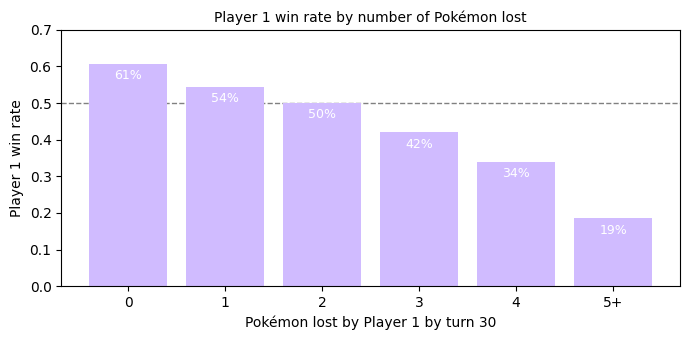

,battles,Player 1 win rate
p1_fainted_count,,
0,2450,60.7%
1,2650,54.4%
2,2194,50.1%
3,1480,42.0%
4,789,34.0%
5+,437,18.5%


In [13]:
p2_fainted_counts = [
    len({turn['p2_pokemon_state']['name']
         for turn in battle['battle_timeline']
         if turn['p2_pokemon_state']['hp_pct'] == 0})
    for battle in train_data
]
print(f"Average Pokémon lost by turn 30: Player 1 {X_v3['p1_fainted_count'].mean():.2f}, "
      f"Player 2 {np.mean(p2_fainted_counts):.2f}")

lost = X_v3['p1_fainted_count'].clip(upper=5).map(lambda n: '5+' if n == 5 else str(n))
lost_summary = pd.DataFrame({
    'battles': lost.value_counts().sort_index(),
    'Player 1 win rate': y.groupby(lost).mean(),
})

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(lost_summary.index, lost_summary['Player 1 win rate'], color='#D0BBFF', zorder=2)
ax.axhline(0.5, color='grey', linestyle='--', linewidth=1, zorder=1)
ax.set_ylim(0, 0.7)
ax.set_xlabel('Pokémon lost by Player 1 by turn 30')
ax.set_ylabel('Player 1 win rate')
ax.set_title('Player 1 win rate by number of Pokémon lost', fontsize=10)
for k, value in enumerate(lost_summary['Player 1 win rate']):
    ax.text(k, value - 0.015, f"{value:.0%}", ha='center', va='top', fontsize=9, color='white', zorder=3)
fig.tight_layout()
plt.show()

display(lost_summary.style.format({'Player 1 win rate': '{:.1%}'}))

### Validation of version 3

Same model and same folds as the previous versions.

In [14]:
scores_v3 = cross_val_score(model, X_v3, y, cv=cv, scoring='accuracy')

comparison_v3 = pd.DataFrame({
    'version 2': scores_v2,
    'version 3': scores_v3,
}, index=[f'fold {k}' for k in range(1, 6)])
comparison_v3['difference (points)'] = 100 * (comparison_v3['version 3'] - comparison_v3['version 2'])
display(comparison_v3.style.format({'version 2': '{:.2%}', 'version 3': '{:.2%}',
                                    'difference (points)': '{:+.2f}'}))

print(f"Version 1: {scores.mean():.2%}   Version 2: {scores_v2.mean():.2%}   Version 3: {scores_v3.mean():.2%}")
print(f"Version 3 is better than version 2 in {(scores_v3 > scores_v2).sum()} of 5 folds, "
      f"by {100 * (scores_v3.mean() - scores_v2.mean()):+.2f} points on average")

,version 2,version 3,difference (points)
fold 1,54.15%,59.45%,+5.30
fold 2,52.45%,57.50%,+5.05
fold 3,54.25%,58.00%,+3.75
fold 4,53.65%,60.40%,+6.75
fold 5,53.70%,58.20%,+4.50


Version 1: 51.78%   Version 2: 53.64%   Version 3: 58.71%
Version 3 is better than version 2 in 5 of 5 folds, by +5.07 points on average


### Submission 3 · Pokémon lost by Player 1

Logistic regression on the version 2 features plus the number of Pokémon lost by Player 1. Cross-validated accuracy rises from about 53.64% to about 58.71%, with a gain in all five folds: the state of the whole team is far more informative than the state of the active Pokémon alone. 

In [15]:
final_model_v3 = LogisticRegression(random_state=SEED, max_iter=1000)
final_model_v3.fit(X_v3, y)   # refit on all 10,000 training battles
test_predictions_v3 = final_model_v3.predict(X_test_v3)

# Predictions are matched to the template by battle_id
predictions_by_id = pd.Series(test_predictions_v3, index=test_df_v3['battle_id'])
submission_df = sample_submission.copy()
submission_df['player_won'] = submission_df['battle_id'].map(predictions_by_id).astype(int)
submission_df.to_csv('submission_v3.csv', index=False)

print("submission_v3.csv created:", submission_df.shape)
display(submission_df.head())

submission_v3.csv created: (5000, 2)


,battle_id,player_won
0,0,1
1,1,1
2,2,1
3,3,1
4,4,0


## Version 4

We add the number of Pokémon lost by Player 2, the number of Pokémon of each team with each status condition (sleep, paralysis, toxic, poison, burn, freeze) and the total stat boosts of the two active Pokémon at turn 30.

In [16]:
STATUSES = ['slp', 'par', 'tox', 'psn', 'brn', 'frz']


def add_condition_features(data, base_df):
    
    rows = []
    for battle in data:
        timeline = battle['battle_timeline']
        features = {}

        features['p2_fainted_count'] = len({
            turn['p2_pokemon_state']['name']
            for turn in timeline
            if turn['p2_pokemon_state']['hp_pct'] == 0
        })

        for side in ('p1', 'p2'):
            last_status = {}
            for turn in timeline:
                state = turn[f'{side}_pokemon_state']
                last_status[state['name']] = state['status']

            for status in STATUSES:
                features[f'{side}_n_{status}'] = sum(s == status for s in last_status.values())

            features[f'{side}_active_boosts'] = sum(timeline[-1][f'{side}_pokemon_state']['boosts'].values())

        rows.append(features)

    return pd.concat([base_df, pd.DataFrame(rows, index=base_df.index)], axis=1)


train_df_v4 = add_condition_features(train_data, train_df_v3)
test_df_v4 = add_condition_features(test_data, test_df_v3)

features_v4 = [col for col in train_df_v4.columns if col not in ['battle_id', 'player_won']]
X_v4 = train_df_v4[features_v4]
X_test_v4 = test_df_v4[features_v4]

print("Train shape:", X_v4.shape, " Test shape:", X_test_v4.shape)

Train shape: (10000, 25)  Test shape: (5000, 25)


### How informative are the new features

For each new feature we compare its average value in the battles won and lost by Player 1.

In [17]:
new_features = [col for col in features_v4 if col not in features_v3]

condition_summary = X_v4[new_features].groupby(y).mean().T
condition_summary.columns = ['Player 1 lost', 'Player 1 won']
condition_summary['difference'] = condition_summary['Player 1 won'] - condition_summary['Player 1 lost']
display(condition_summary.style.format('{:.3f}'))

,Player 1 lost,Player 1 won,difference
p2_fainted_count,0.487,0.521,0.035
p1_n_slp,0.556,0.554,-0.002
p1_n_par,0.254,0.256,0.002
p1_n_tox,0.120,0.121,0.001
p1_n_psn,0.086,0.085,-0.001
p1_n_brn,0.008,0.008,0.000
p1_n_frz,0.017,0.013,-0.004
p1_active_boosts,0.217,0.337,0.120
p2_n_slp,0.598,0.673,0.075
p2_n_par,0.328,0.416,0.088


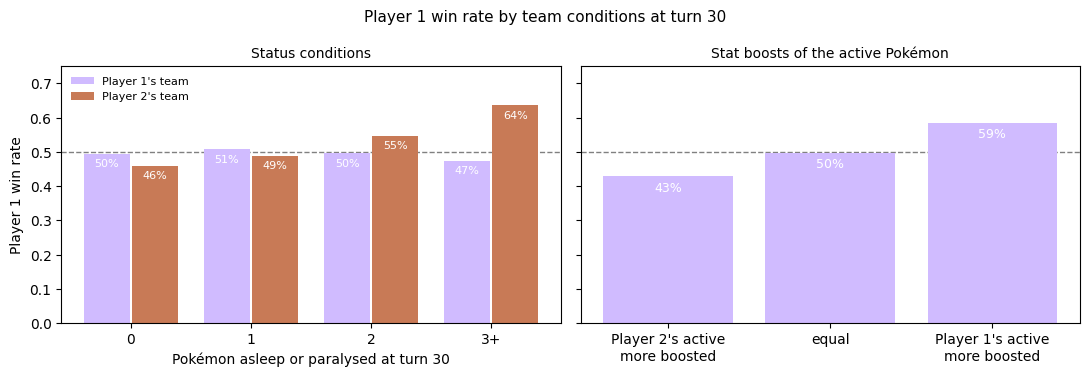

In [18]:
fig, (ax_status, ax_boost) = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)

# Left: Player 1 win rate by the number of Pokémon asleep or paralysed in each team
groups = ['0', '1', '2', '3+']
positions = np.arange(len(groups))
width = 0.38
for offset, side, label, color in ((-0.2, 'p1', "Player 1's team", '#D0BBFF'),
                                   (0.2, 'p2', "Player 2's team", '#C87A56')):
    disabled = (X_v4[f'{side}_n_slp'] + X_v4[f'{side}_n_par']).clip(upper=3)
    win_rate = y.groupby(disabled).mean().reindex(range(4))
    ax_status.bar(positions + offset, win_rate.values, width, color=color, label=label, zorder=2)
    for x_pos, value in zip(positions + offset, win_rate.values):
        ax_status.text(x_pos, value - 0.015, f"{value:.0%}", ha='center', va='top',
                       fontsize=8, color='white', zorder=3)
ax_status.set_xticks(positions, groups)
ax_status.set_xlabel('Pokémon asleep or paralysed at turn 30')
ax_status.set_ylabel('Player 1 win rate')
ax_status.set_title('Status conditions', fontsize=10)
ax_status.legend(frameon=False, fontsize=8, loc='upper left')

# Right: Player 1 win rate by which active Pokémon has more stat boosts
boost_diff = X_v4['p1_active_boosts'] - X_v4['p2_active_boosts']
boost_group = pd.cut(boost_diff, bins=[-np.inf, -0.5, 0.5, np.inf],
                     labels=["Player 2's active\nmore boosted", 'equal', "Player 1's active\nmore boosted"])
boost_rate = y.groupby(boost_group, observed=True).mean()
ax_boost.bar(boost_rate.index.astype(str), boost_rate.values, color='#D0BBFF', zorder=2)
for k, value in enumerate(boost_rate.values):
    ax_boost.text(k, value - 0.015, f"{value:.0%}", ha='center', va='top',
                  fontsize=9, color='white', zorder=3)
ax_boost.set_title('Stat boosts of the active Pokémon', fontsize=10)

for ax in (ax_status, ax_boost):
    ax.axhline(0.5, color='grey', linestyle='--', linewidth=1, zorder=1)
    ax.set_ylim(0, 0.75)

fig.suptitle('Player 1 win rate by team conditions at turn 30', fontsize=11)
fig.tight_layout()
plt.show()

### Validation of version 4

From this version on the features are standardised inside a pipeline (`StandardScaler` + logistic regression): with features on very different scales the solver did not converge. The scaler is part of the model, so in cross-validation it is fitted on the training folds only. On the version 3 features standardisation does not change the accuracy.

In [19]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

model_v4 = make_pipeline(StandardScaler(), LogisticRegression(random_state=SEED, max_iter=1000))

scores_v3_scaled = cross_val_score(model_v4, X_v3, y, cv=cv, scoring='accuracy')
scores_v4 = cross_val_score(model_v4, X_v4, y, cv=cv, scoring='accuracy')
print(f"Version 3 without / with standardisation: {scores_v3.mean():.2%} / {scores_v3_scaled.mean():.2%}\n")

comparison_v4 = pd.DataFrame({
    'version 3': scores_v3,
    'version 4': scores_v4,
}, index=[f'fold {k}' for k in range(1, 6)])
comparison_v4['difference (points)'] = 100 * (comparison_v4['version 4'] - comparison_v4['version 3'])
display(comparison_v4.style.format({'version 3': '{:.2%}', 'version 4': '{:.2%}',
                                    'difference (points)': '{:+.2f}'}))

summary = pd.DataFrame({
    'version': ['1 · baseline', '2 · active HP', '3 · Player 1 losses', '4 · Player 2 losses and conditions'],
    'features': [X.shape[1], X_v2.shape[1], X_v3.shape[1], X_v4.shape[1]],
    'CV accuracy': [scores.mean(), scores_v2.mean(), scores_v3.mean(), scores_v4.mean()],
})
display(summary.style.format({'CV accuracy': '{:.2%}'}).hide(axis='index'))

print(f"Version 4 is better than version 3 in {(scores_v4 > scores_v3).sum()} of 5 folds, "
      f"by {100 * (scores_v4.mean() - scores_v3.mean()):+.2f} points on average")

Version 3 without / with standardisation: 58.71% / 58.71%



,version 3,version 4,difference (points)
fold 1,59.45%,62.90%,+3.45
fold 2,57.50%,63.15%,+5.65
fold 3,58.00%,62.45%,+4.45
fold 4,60.40%,64.10%,+3.70
fold 5,58.20%,63.00%,+4.80


version,features,CV accuracy
1 · baseline,6,51.78%
2 · active HP,9,53.64%
3 · Player 1 losses,10,58.71%
4 · Player 2 losses and conditions,25,63.12%


Version 4 is better than version 3 in 5 of 5 folds, by +4.41 points on average


### Submission 4 · Player 2's losses and team conditions

Standardised logistic regression on the version 3 features plus Player 2's losses, the status conditions of both teams and the boosts of the active Pokémon. Cross-validated accuracy rises from about 58.71% to about 63.12%, with a gain in all five folds.

In [20]:
final_model_v4 = make_pipeline(StandardScaler(), LogisticRegression(random_state=SEED, max_iter=1000))
final_model_v4.fit(X_v4, y)   # refit on all 10,000 training battles
test_predictions_v4 = final_model_v4.predict(X_test_v4)


predictions_by_id = pd.Series(test_predictions_v4, index=test_df_v4['battle_id'])
submission_df = sample_submission.copy()
submission_df['player_won'] = submission_df['battle_id'].map(predictions_by_id).astype(int)
submission_df.to_csv('submission_v4.csv', index=False)

print("submission_v4.csv created:", submission_df.shape)
display(submission_df.head())

submission_v4.csv created: (5000, 2)


,battle_id,player_won
0,0,1
1,1,0
2,2,0
3,3,1
4,4,0


## Version 5

For each player we count the Pokémon in good shape at turn 30: at least 50% HP and no status condition. Player 2's Pokémon not yet revealed count as healthy.

In [21]:
def add_healthy_features(data, base_df):
    
    rows = []
    for battle in data:
        features = {}
        for side in ('p1', 'p2'):
            last_state = {}
            for turn in battle['battle_timeline']:
                state = turn[f'{side}_pokemon_state']
                last_state[state['name']] = state

            never_seen = 6 - len(last_state)
            features[f'{side}_healthy_count'] = never_seen + sum(
                state['status'] == 'nostatus' and state['hp_pct'] >= 0.5
                for state in last_state.values()
            )
        rows.append(features)

    return pd.concat([base_df, pd.DataFrame(rows, index=base_df.index)], axis=1)


train_df_v5 = add_healthy_features(train_data, train_df_v4)
test_df_v5 = add_healthy_features(test_data, test_df_v4)

features_v5 = [col for col in train_df_v5.columns if col not in ['battle_id', 'player_won']]
X_v5 = train_df_v5[features_v5]
X_test_v5 = test_df_v5[features_v5]

print("Train shape:", X_v5.shape, " Test shape:", X_test_v5.shape)
print(f"Average Pokémon in good shape at turn 30: Player 1 {X_v5['p1_healthy_count'].mean():.2f}, "
      f"Player 2 {X_v5['p2_healthy_count'].mean():.2f}")

Train shape: (10000, 27)  Test shape: (5000, 27)
Average Pokémon in good shape at turn 30: Player 1 2.77, Player 2 3.14


### How informative is the number of Pokémon in good shape

We look at Player 1's win rate as a function of the difference between the two counts (Player 1 minus Player 2).

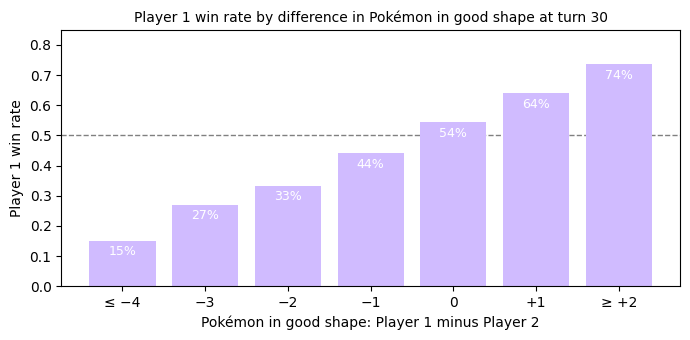

,battles,Player 1 win rate
≤ −4,284,15.1%
−3,719,27.0%
−2,1468,33.2%
−1,2223,44.1%
0,2322,54.3%
+1,1673,64.0%
≥ +2,1311,73.5%


In [22]:
healthy_diff = (X_v5['p1_healthy_count'] - X_v5['p2_healthy_count']).clip(-4, 2)
labels = {-4: '≤ −4', -3: '−3', -2: '−2', -1: '−1', 0: '0', 1: '+1', 2: '≥ +2'}
healthy_summary = pd.DataFrame({
    'battles': healthy_diff.value_counts().sort_index(),
    'Player 1 win rate': y.groupby(healthy_diff).mean(),
}).rename(index=labels)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(healthy_summary.index, healthy_summary['Player 1 win rate'], color='#D0BBFF', zorder=2)
ax.axhline(0.5, color='grey', linestyle='--', linewidth=1, zorder=1)
ax.set_ylim(0, 0.85)
ax.set_xlabel('Pokémon in good shape: Player 1 minus Player 2')
ax.set_ylabel('Player 1 win rate')
ax.set_title('Player 1 win rate by difference in Pokémon in good shape at turn 30', fontsize=10)
for k, value in enumerate(healthy_summary['Player 1 win rate']):
    ax.text(k, value - 0.015, f"{value:.0%}", ha='center', va='top', fontsize=9, color='white', zorder=3)
fig.tight_layout()
plt.show()

display(healthy_summary.style.format({'Player 1 win rate': '{:.1%}'}))

### Validation of version 5

Same standardised logistic regression and same folds as version 4.

In [23]:
scores_v5 = cross_val_score(model_v4, X_v5, y, cv=cv, scoring='accuracy')

comparison_v5 = pd.DataFrame({
    'version 4': scores_v4,
    'version 5': scores_v5,
}, index=[f'fold {k}' for k in range(1, 6)])
comparison_v5['difference (points)'] = 100 * (comparison_v5['version 5'] - comparison_v5['version 4'])
display(comparison_v5.style.format({'version 4': '{:.2%}', 'version 5': '{:.2%}',
                                    'difference (points)': '{:+.2f}'}))

summary = pd.DataFrame({
    'version': ['1 · baseline', '2 · active HP', '3 · Player 1 losses',
                '4 · Player 2 losses and conditions', '5 · Pokémon in good shape'],
    'features': [X.shape[1], X_v2.shape[1], X_v3.shape[1], X_v4.shape[1], X_v5.shape[1]],
    'CV accuracy': [scores.mean(), scores_v2.mean(), scores_v3.mean(), scores_v4.mean(), scores_v5.mean()],
})
display(summary.style.format({'CV accuracy': '{:.2%}'}).hide(axis='index'))

print(f"Version 5 is better than version 4 in {(scores_v5 > scores_v4).sum()} of 5 folds, "
      f"by {100 * (scores_v5.mean() - scores_v4.mean()):+.2f} points on average")

,version 4,version 5,difference (points)
fold 1,62.90%,66.10%,+3.20
fold 2,63.15%,65.10%,+1.95
fold 3,62.45%,64.45%,+2.00
fold 4,64.10%,65.05%,+0.95
fold 5,63.00%,65.20%,+2.20


version,features,CV accuracy
1 · baseline,6,51.78%
2 · active HP,9,53.64%
3 · Player 1 losses,10,58.71%
4 · Player 2 losses and conditions,25,63.12%
5 · Pokémon in good shape,27,65.18%


Version 5 is better than version 4 in 5 of 5 folds, by +2.06 points on average


### Submission 5 · Pokémon in good shape

Standardised logistic regression on the version 4 features plus the number of Pokémon in good shape for each player. Cross-validated accuracy rises from about 63.12% to about 65.18%, with a gain in all five folds.

In [24]:
final_model_v5 = make_pipeline(StandardScaler(), LogisticRegression(random_state=SEED, max_iter=1000))
final_model_v5.fit(X_v5, y)   # refit on all 10,000 training battles
test_predictions_v5 = final_model_v5.predict(X_test_v5)


predictions_by_id = pd.Series(test_predictions_v5, index=test_df_v5['battle_id'])
submission_df = sample_submission.copy()
submission_df['player_won'] = submission_df['battle_id'].map(predictions_by_id).astype(int)
submission_df.to_csv('submission_v5.csv', index=False)

print("submission_v5.csv created:", submission_df.shape)
display(submission_df.head())

submission_v5.csv created: (5000, 2)


,battle_id,player_won
0,0,1
1,1,0
2,2,0
3,3,1
4,4,1


## Version 6

Three groups of features:
- **Remaining HP of each whole team** at turn 30 (Pokémon not yet seen count as full HP), and how the HP difference changed over the last ten turns.
- **Type effectiveness of the attacks**, from the supplied Gen 2 type chart: for each player, the attacks that were super effective or resisted, the status moves and the mean base power.
- **Moves used**: for each player, how many times each of the 58 most frequent moves was used.

The species-to-types table and the list of frequent moves are built from the training set only and do not involve the target.

In [25]:
def team_hp(timeline, side):
    '''Remaining HP of a whole team, in full Pokémon (6 = all six at full HP).

    Pokémon not yet seen in the given turns count as full HP.
    '''
    last_hp = {}
    for turn in timeline:
        state = turn[f'{side}_pokemon_state']
        last_hp[state['name']] = state['hp_pct']
    never_seen = 6 - len(last_hp)
    return sum(last_hp.values()) + never_seen


def add_team_hp_features(data, base_df):
    '''Add the remaining HP of both teams at turn 30 and the change of the HP difference since turn 20.'''
    rows = []
    for battle in data:
        timeline = battle['battle_timeline']
        p1_hp_30, p2_hp_30 = team_hp(timeline, 'p1'), team_hp(timeline, 'p2')
        p1_hp_20, p2_hp_20 = team_hp(timeline[:20], 'p1'), team_hp(timeline[:20], 'p2')
        rows.append({
            'p1_team_hp': p1_hp_30,
            'p2_team_hp': p2_hp_30,
            'team_hp_diff_change_last10': (p1_hp_30 - p2_hp_30) - (p1_hp_20 - p2_hp_20),
        })

    return pd.concat([base_df, pd.DataFrame(rows, index=base_df.index)], axis=1)


# Lookup tables built from the training set only (the target is not used)
type_multiplier = {
    (row.attacking_type, row.defending_type): row.multiplier
    for row in type_chart.itertuples(index=False)
}

species_types = {}
for battle in train_data:
    for pokemon in battle['p1_team_details'] + [battle['p2_lead_details']]:
        species_types[pokemon['name']] = pokemon['types']

move_usage = collections.Counter(
    turn[f'{side}_move_details']['name']
    for battle in train_data
    for turn in battle['battle_timeline']
    for side in ('p1', 'p2')
    if turn[f'{side}_move_details']
)
frequent_moves = sorted(name for name, count in move_usage.items() if count >= 1000)
print(f"Species in the type table: {len(species_types)}   Frequent moves: {len(frequent_moves)}")


def effectiveness(move_type, defender_types):
    '''Damage multiplier of a move type against a Pokémon with the given types.'''
    multiplier = 1.0
    for defender_type in defender_types:
        if defender_type != 'notype':
            multiplier *= type_multiplier.get((move_type, defender_type), 1.0)
    return multiplier


def add_move_features(data, base_df):
    '''Add type effectiveness, status moves, mean base power and usage of the frequent moves.

    The defender's types come from the species table built on the training set;
    unknown species count as neutral.
    '''
    rows = []
    for battle in data:
        timeline = battle['battle_timeline']
        features = {}

        for side, opponent in (('p1', 'p2'), ('p2', 'p1')):
            super_effective = resisted = status_moves = 0
            powers = []
            used = collections.Counter()

            for turn in timeline:
                move = turn[f'{side}_move_details']
                if move is None:
                    continue
                used[move['name']] += 1
                if move['category'] == 'status':
                    status_moves += 1
                elif move['base_power'] > 0:
                    powers.append(move['base_power'])
                    defender = turn[f'{opponent}_pokemon_state']['name']
                    multiplier = effectiveness(move['type'], species_types.get(defender, ['notype']))
                    super_effective += multiplier > 1
                    resisted += multiplier < 1

            features[f'{side}_super_effective'] = super_effective
            features[f'{side}_resisted'] = resisted
            features[f'{side}_status_moves'] = status_moves
            features[f'{side}_mean_power'] = np.mean(powers) if powers else 0.0
            for move_name in frequent_moves:
                features[f'{side}_move_{move_name}'] = used[move_name]

        rows.append(features)

    return pd.concat([base_df, pd.DataFrame(rows, index=base_df.index)], axis=1)


train_df_v6 = add_move_features(train_data, add_team_hp_features(train_data, train_df_v5))
test_df_v6 = add_move_features(test_data, add_team_hp_features(test_data, test_df_v5))

features_v6 = [col for col in train_df_v6.columns if col not in ['battle_id', 'player_won']]
X_v6 = train_df_v6[features_v6]
X_test_v6 = test_df_v6[features_v6]

print("Train shape:", X_v6.shape, " Test shape:", X_test_v6.shape)
print(f"Average remaining team HP at turn 30: Player 1 {X_v6['p1_team_hp'].mean():.2f}, "
      f"Player 2 {X_v6['p2_team_hp'].mean():.2f} (out of 6)")

Species in the type table: 239   Frequent moves: 58
Train shape: (10000, 154)  Test shape: (5000, 154)
Average remaining team HP at turn 30: Player 1 3.43, Player 2 4.00 (out of 6)


### How informative are remaining HP and its trend

Left: Player 1's win rate by the difference in remaining team HP at turn 30 (Player 1 minus Player 2). Right: Player 1's win rate by how that difference changed over the last ten turns.

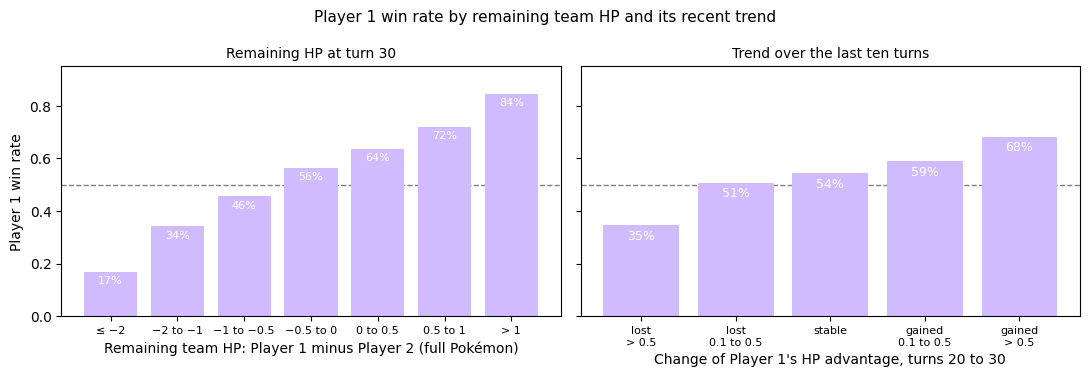

In [26]:
fig, (ax_hp, ax_trend) = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)

hp_diff = X_v6['p1_team_hp'] - X_v6['p2_team_hp']
hp_groups = pd.cut(hp_diff, bins=[-np.inf, -2, -1, -0.5, 0, 0.5, 1, np.inf],
                   labels=['≤ −2', '−2 to −1', '−1 to −0.5', '−0.5 to 0', '0 to 0.5', '0.5 to 1', '> 1'])
hp_rate = y.groupby(hp_groups, observed=True).mean()
ax_hp.bar(hp_rate.index.astype(str), hp_rate.values, color='#D0BBFF', zorder=2)
for k, value in enumerate(hp_rate.values):
    ax_hp.text(k, value - 0.015, f"{value:.0%}", ha='center', va='top', fontsize=8, color='white', zorder=3)
ax_hp.set_xlabel('Remaining team HP: Player 1 minus Player 2 (full Pokémon)')
ax_hp.set_ylabel('Player 1 win rate')
ax_hp.set_title('Remaining HP at turn 30', fontsize=10)
ax_hp.tick_params(axis='x', labelsize=8)

trend_groups = pd.cut(X_v6['team_hp_diff_change_last10'], bins=[-np.inf, -0.5, -0.1, 0.1, 0.5, np.inf],
                      labels=['lost\n> 0.5', 'lost\n0.1 to 0.5', 'stable', 'gained\n0.1 to 0.5', 'gained\n> 0.5'])
trend_rate = y.groupby(trend_groups, observed=True).mean()
ax_trend.bar(trend_rate.index.astype(str), trend_rate.values, color='#D0BBFF', zorder=2)
for k, value in enumerate(trend_rate.values):
    ax_trend.text(k, value - 0.015, f"{value:.0%}", ha='center', va='top', fontsize=9, color='white', zorder=3)
ax_trend.set_xlabel("Change of Player 1's HP advantage, turns 20 to 30")
ax_trend.set_title('Trend over the last ten turns', fontsize=10)
ax_trend.tick_params(axis='x', labelsize=8)

for ax in (ax_hp, ax_trend):
    ax.axhline(0.5, color='grey', linestyle='--', linewidth=1, zorder=1)
    ax.set_ylim(0, 0.95)

fig.suptitle('Player 1 win rate by remaining team HP and its recent trend', fontsize=11)
fig.tight_layout()
plt.show()

### How informative are the moves

For each move feature we compute its correlation with Player 1's victory on the training set and plot the six most positive and the six most negative ones.

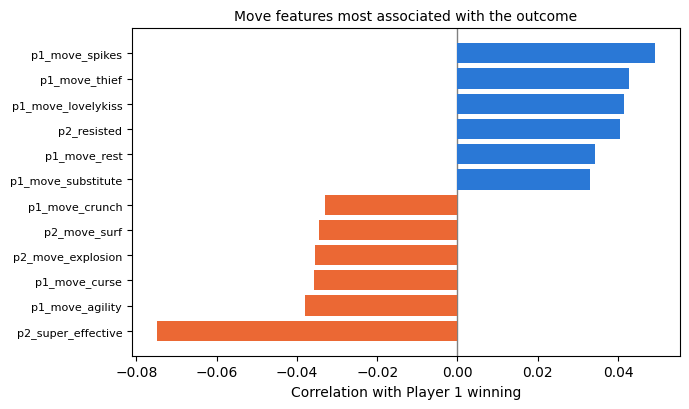

Largest absolute correlation among the move features: 0.075


In [27]:
team_hp_features = ['p1_team_hp', 'p2_team_hp', 'team_hp_diff_change_last10']
new_move_features = [col for col in features_v6 if col not in features_v5 and col not in team_hp_features]
correlations = X_v6[new_move_features].apply(
    lambda col: np.corrcoef(col, y)[0, 1] if col.std() > 0 else 0.0
).sort_values()
top = pd.concat([correlations.head(6), correlations.tail(6)])

fig, ax = plt.subplots(figsize=(7, 4.2))
colors = ['#eb6834' if value < 0 else '#2a78d6' for value in top.values]
ax.barh(top.index, top.values, color=colors, zorder=2)
ax.axvline(0, color='grey', linewidth=1, zorder=1)
ax.set_xlabel('Correlation with Player 1 winning')
ax.set_title('Move features most associated with the outcome', fontsize=10)
ax.tick_params(axis='y', labelsize=8)
fig.tight_layout()
plt.show()

print(f"Largest absolute correlation among the move features: {correlations.abs().max():.3f}")

### Validation of version 6

Same standardised logistic regression and same folds as versions 4 and 5.

In [28]:
scores_v6 = cross_val_score(model_v4, X_v6, y, cv=cv, scoring='accuracy')

comparison_v6 = pd.DataFrame({
    'version 5': scores_v5,
    'version 6': scores_v6,
}, index=[f'fold {k}' for k in range(1, 6)])
comparison_v6['difference (points)'] = 100 * (comparison_v6['version 6'] - comparison_v6['version 5'])
display(comparison_v6.style.format({'version 5': '{:.2%}', 'version 6': '{:.2%}',
                                    'difference (points)': '{:+.2f}'}))

summary = pd.DataFrame({
    'version': ['1 · baseline', '2 · active HP', '3 · Player 1 losses',
                '4 · Player 2 losses and conditions', '5 · Pokémon in good shape',
                '6 · whole-team HP and moves'],
    'features': [X.shape[1], X_v2.shape[1], X_v3.shape[1], X_v4.shape[1], X_v5.shape[1], X_v6.shape[1]],
    'CV accuracy': [scores.mean(), scores_v2.mean(), scores_v3.mean(),
                    scores_v4.mean(), scores_v5.mean(), scores_v6.mean()],
})
display(summary.style.format({'CV accuracy': '{:.2%}'}).hide(axis='index'))

print(f"Version 6 is better than version 5 in {(scores_v6 > scores_v5).sum()} of 5 folds, "
      f"by {100 * (scores_v6.mean() - scores_v5.mean()):+.2f} points on average")

,version 5,version 6,difference (points)
fold 1,66.10%,68.20%,+2.10
fold 2,65.10%,67.50%,+2.40
fold 3,64.45%,67.95%,+3.50
fold 4,65.05%,69.40%,+4.35
fold 5,65.20%,66.25%,+1.05


version,features,CV accuracy
1 · baseline,6,51.78%
2 · active HP,9,53.64%
3 · Player 1 losses,10,58.71%
4 · Player 2 losses and conditions,25,63.12%
5 · Pokémon in good shape,27,65.18%
6 · whole-team HP and moves,154,67.86%


Version 6 is better than version 5 in 5 of 5 folds, by +2.68 points on average


### Submission 6 · Whole-team HP, type effectiveness and moves

Standardised logistic regression on the 154 features of version 6, refitted on all 10,000 labelled battles. Cross-validated accuracy rises from about 65.18% to about 67.86%, with a gain in all five folds. This is our final logistic regression submission.

In [29]:
final_model_v6 = make_pipeline(StandardScaler(), LogisticRegression(random_state=SEED, max_iter=1000))
final_model_v6.fit(X_v6, y)   # refit on all 10,000 training battles
test_predictions_v6 = final_model_v6.predict(X_test_v6)

# Save the final predictions as submission.csv; they are matched by battle_id
predictions_by_id = pd.Series(test_predictions_v6, index=test_df_v6['battle_id'])
submission_df = sample_submission.copy()
submission_df['player_won'] = submission_df['battle_id'].map(predictions_by_id).astype(int)
submission_df.to_csv('submission.csv', index=False)

print("submission.csv created:", submission_df.shape)
display(submission_df.head())

submission.csv created: (5000, 2)


,battle_id,player_won
0,0,1
1,1,0
2,2,0
3,3,0
4,4,1
